# Exploración AML 2: Sensores de Caudal y Recurrencia de Pares

## 1. Pregunta de Negocio y Objetivos
**Pregunta central:** ¿El vaciado parcial (`ratio_vaciado`) y la recurrencia entre pares origen-destino (`frecuencia_conexion`) aportan señal adicional a la regla de vaciado total (`flag_vaciado`) para detectar operaciones de *layering*?

**Objetivo técnico:**
1. Evaluar si los defraudadores extraen fondos de forma fraccionada para evadir umbrales rígidos del 100%.
2. Determinar si la frecuencia de conexión aísla estructuras de repetición o si genera falsos positivos frente a operaciones legítimas recurrentes (ej. nóminas).
3. Entregar un dataset procesado (`paysim_features_v2.parquet`) rigurosamente auditado y libre de contaminación sintética para el modelado en XGBoost (Notebook 3).

## 2. Carga del Flujo y Verificación de Topología
Cargamos la salida procesada del Notebook 1 (`paysim_features.parquet`) y verificamos contractualmente la existencia de las variables base (`in_degree`, `out_degree`, `flag_vaciado`).

In [33]:
import pandas as pd
import numpy as np

# 1. Carga de datos
ruta_origen = '../data/processed/paysim_features.parquet'
df = pd.read_parquet(ruta_origen)

# 2. Verificación de dimensiones y balance de clases
print(f"Dimensiones del dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("\nDistribución de la variable objetivo (isFraud):")
conteo_clases = df['isFraud'].value_counts()
proporciones = df['isFraud'].value_counts(normalize=True) * 100
resumen_clases = pd.DataFrame({'Total': conteo_clases, 'Porcentaje (%)': proporciones.round(4)})
display(resumen_clases)

# 3. Contrato de datos: comprobamos que las columnas clave existen
columnas_requeridas = ['in_degree', 'out_degree', 'flag_vaciado', 'oldbalanceOrg', 'amount', 'nameOrig', 'nameDest']
columnas_faltantes = [col for col in columnas_requeridas if col not in df.columns]

assert len(columnas_faltantes) == 0, f"Error en pipeline: Faltan las columnas {columnas_faltantes}"
print("\nVerificación de contrato exitosa: Todas las variables topológicas y contables están presentes.")

Dimensiones del dataset: 2,770,409 filas x 17 columnas

Distribución de la variable objetivo (isFraud):


,Total,Porcentaje (%)
isFraud,,
0,2762196,99.7035
1,8213,0.2965



Verificación de contrato exitosa: Todas las variables topológicas y contables están presentes.


## 3. Chequeo de Calidad e Integridad Contable
Antes de construir los sensores, auditamos la presencia de valores nulos, registros negativos y transacciones donde el monto transferido supera el saldo disponible (`amount > oldbalanceOrg`). Esto permite registrar posibles artefactos o inconsistencias del simulador PaySim.

In [34]:
# 1. Chequeo de valores nulos
nulos = df[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']].isnull().sum()
print("Valores nulos en variables financieras:")
print(nulos)

# 2. Chequeo de valores negativos
negativos = (df[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']] < 0).sum()
print("\nValores negativos en variables financieras:")
print(negativos)

# 3. Auditoría de transacciones con monto superior al saldo origen
sobregiro_legitimo = ((df['isFraud'] == 0) & (df['amount'] > df['oldbalanceOrg'])).sum()
sobregiro_fraude = ((df['isFraud'] == 1) & (df['amount'] > df['oldbalanceOrg'])).sum()

total_fraudes = (df['isFraud'] == 1).sum()
pct_fraude_sobregiro = (sobregiro_fraude / total_fraudes) * 100

print(f"\nTransacciones donde amount > oldbalanceOrg:")
print(f"- En operaciones legítimas: {sobregiro_legitimo:,}")
print(f"- En operaciones de fraude:  {sobregiro_fraude:,} de {total_fraudes:,} ({pct_fraude_sobregiro:.2f}%)")

Valores nulos en variables financieras:
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64

Valores negativos en variables financieras:
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64

Transacciones donde amount > oldbalanceOrg:
- En operaciones legítimas: 2,488,605
- En operaciones de fraude:  29 de 8,213 (0.35%)


### Hallazgos de Integridad Contable
- **Valores nulos y negativos:** Inexistentes en las variables analizadas.
- **Inconsistencia de saldo (`amount > oldbalanceOrg`):** Ocurre únicamente en 29 operaciones de fraude (0.35%), lo que explica los valores atípicos del ratio (> 1.0) sin comprometer la tendencia central del 100%. En operaciones legítimas es un comportamiento habitual asociado a cuentas con saldo inicial cero que operan como canales de paso.

---

## 4. Sensor de Caudal: Ratio de Vaciado
Calculamos la proporción de fondos drenados respecto al saldo de origen (`amount / oldbalanceOrg`), protegiendo la operación frente a divisiones por cero mediante `np.where`.

In [35]:
# 1. Cálculo del sensor de caudal continuo
df['ratio_vaciado'] = np.where(
    df['oldbalanceOrg'] > 0,
    df['amount'] / df['oldbalanceOrg'],
    0.0
)

# 2. Distribución estadística por clase (Legítimo vs Fraude)
print("Distribución de ratio_vaciado en Operaciones Legítimas (isFraud = 0):")
display(df[df['isFraud'] == 0]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4))

print("\nDistribución de ratio_vaciado en Operaciones de Fraude (isFraud = 1):")
display(df[df['isFraud'] == 1]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4))

# 3. Conteo de fraudes que quedan fuera de la regla binaria del 100%
fraudes_totales = (df['isFraud'] == 1).sum()
fraudes_vaciado_exacto = ((df['isFraud'] == 1) & (df['flag_vaciado'] == 1)).sum()
fraudes_parciales = ((df['isFraud'] == 1) & (df['flag_vaciado'] == 0)).sum()

print(f"\nResumen del fraude frente a la regla binaria (flag_vaciado == 1):")
print(f"- Vaciado exacto al 100%: {fraudes_vaciado_exacto:,} ({fraudes_vaciado_exacto / fraudes_totales * 100:.2f}%)")
print(f"- Vaciado parcial / fuera de regla: {fraudes_parciales:,} ({fraudes_parciales / fraudes_totales * 100:.2f}%)")

Distribución de ratio_vaciado en Operaciones Legítimas (isFraud = 0):


count    2.762196e+06
mean     1.459728e+02
std      4.967900e+03
min      0.000000e+00
10%      0.000000e+00
25%      0.000000e+00
50%      2.203000e-01
75%      6.540400e+00
90%      4.091790e+01
99%      1.944447e+03
max      3.925476e+06
Name: ratio_vaciado, dtype: float64


Distribución de ratio_vaciado en Operaciones de Fraude (isFraud = 1):


count    8213.0000
mean        0.9938
std         0.3908
min         0.0000
10%         1.0000
25%         1.0000
50%         1.0000
75%         1.0000
90%         1.0000
99%         1.0000
max        29.5266
Name: ratio_vaciado, dtype: float64


Resumen del fraude frente a la regla binaria (flag_vaciado == 1):
- Vaciado exacto al 100%: 8,034 (97.82%)
- Vaciado parcial / fuera de regla: 179 (2.18%)


### Visualización del Sensor de Caudal
Comparamos la distribución acumulada empírica (ECDF) o histograma del `ratio_vaciado` entre clases para evaluar visualmente si existe una zona de transición de "vaciado parcial" o si la señal es puramente binaria.

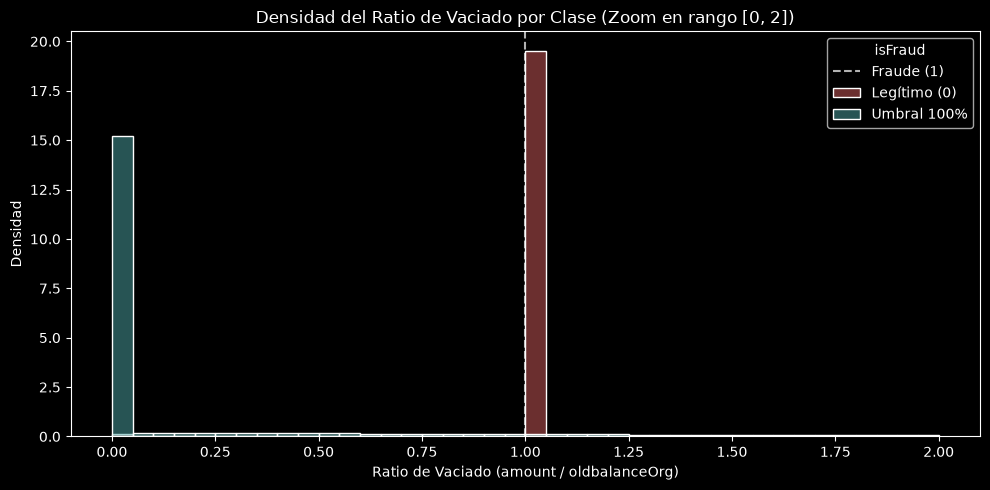

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 5))

# Graficamos la distribución del ratio de vaciado acotando el rango a [0, 2] para inspeccionar la zona crítica
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2],
    x='ratio_vaciado',
    hue='isFraud',
    bins=40,
    stat='density',
    common_norm=False,
    palette=['#4fa8a8', '#d65f5f'],
    ax=ax
)

ax.set_title('Densidad del Ratio de Vaciado por Clase (Zoom en rango [0, 2])')
ax.set_xlabel('Ratio de Vaciado (amount / oldbalanceOrg)')
ax.set_ylabel('Densidad')
ax.axvline(1.0, color='white', linestyle='--', alpha=0.7, label='Umbral 100% (flag_vaciado)')
ax.legend(title='isFraud', labels=['Fraude (1)', 'Legítimo (0)', 'Umbral 100%'])

plt.tight_layout()
plt.show()

### Conclusión del Sensor de Caudal
1. **Poder de separación:** En el fraude, el 97.8% de las transacciones (8,034 de 8,213) tienen exactamente un `ratio_vaciado` de 1.0.
2. **Inexistencia de vaciado parcial sistemático:** No existe evidencia de un patrón de ataque fraccionado o sub-umbral (ej. 80% o 90%) en PaySim. El comportamiento de los atacantes en este dataset es de extracción binaria absoluta.
3. **Utilidad en el modelo:** Aunque el vaciado parcial no aporta una señal oculta relevante en estos datos, mantener `ratio_vaciado` como variable continua le entrega al modelo una frontera suave frente a posibles errores contables o anomalías menores.

## 5. Sensor de Recurrencia en Datos Reales
En tipologías de *layering* o lavado por goteo, un mismo par origen-destino suele registrar transacciones recurrentes. Calculamos la frecuencia de conexión de cada par `(nameOrig, nameDest)` para evaluar si esta señal existe en el dataset real.

In [38]:
# 1. Conteo directo e idempotente por par origen-destino sin merge
df['frecuencia_conexion'] = df.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 2. Distribución empírica de la frecuencia en datos reales
print("Estadísticas de frecuencia_conexion por clase:")
resumen_recurrencia = df.groupby('isFraud')['frecuencia_conexion'].agg(['count', 'min', 'mean', 'max'])
display(resumen_recurrencia)

# 3. Verificación de pares repetidos
pares_repetidos_legitimos = ((df['isFraud'] == 0) & (df['frecuencia_conexion'] > 1)).sum()
pares_repetidos_fraude = ((df['isFraud'] == 1) & (df['frecuencia_conexion'] > 1)).sum()

print(f"\nTransacciones con frecuencia > 1:")
print(f"- Operaciones legítimas repetidas: {pares_repetidos_legitimos}")
print(f"- Operaciones de fraude repetidas:   {pares_repetidos_fraude}")

Estadísticas de frecuencia_conexion por clase:


,count,min,mean,max
isFraud,,,,
0,2762196,1,1.0,1
1,8213,1,1.0,1



Transacciones con frecuencia > 1:
- Operaciones legítimas repetidas: 0
- Operaciones de fraude repetidas:   0


## 6. Validación Conceptual con Casos Controlados (Entorno Aislado)
Dado que PaySim carece de pares repetidos en sus datos base, implementamos un entorno de prueba aislado sobre una copia (`df_sim`). 

Diseñamos dos escenarios para medir la efectividad y el riesgo de falsos positivos de `frecuencia_conexion`:
1. **Caso Mula (*Layering* fraudulento):** Repetición de transferencias con vaciado total de saldo (`flag_vaciado = 1`, `ratio_vaciado = 1.0`).
2. **Caso Nómina (Control legítimo recurrente):** Repetición de transferencias periódicas sin vaciado de cuenta (`flag_vaciado = 0`, `ratio_vaciado = 0.2`).

*Regla de integridad:* Esta inyección opera únicamente en `df_sim` para evitar fuga de datos (*data leakage*) hacia el archivo final de exportación.

In [39]:
# 1. Creamos una copia aislada de prueba
df_sim = df.copy()

# 2. Diseñamos el caso A: Mula de lavado (5 transferencias repetidas con vaciado total)
mula_sintetica = pd.DataFrame([{
    'step': step, 'type': 'TRANSFER', 'amount': 1000.0,
    'nameOrig': "C_MULA_TEST", 'oldbalanceOrg': 1000.0, 'newbalanceOrig': 0.0,
    'nameDest': "C_ESTANQUE_TEST", 'oldbalanceDest': 0.0, 'newbalanceDest': 1000.0,
    'isFraud': 1, 'isFlaggedFraud': 0, 'in_degree': 1, 'out_degree': 1,
    'flag_vaciado': 1, 'ratio_vaciado': 1.0
} for step in range(1, 6)])

# 3. Diseñamos el caso B: Pago de nómina recurrente (5 transferencias legítimas sin vaciado)
nomina_sintetica = pd.DataFrame([{
    'step': step, 'type': 'TRANSFER', 'amount': 1500.0,
    'nameOrig': "C_EMPRESA_TEST", 'oldbalanceOrg': 10000.0, 'newbalanceOrig': 8500.0,
    'nameDest': "C_EMPLEADO_TEST", 'oldbalanceDest': 500.0, 'newbalanceDest': 2000.0,
    'isFraud': 0, 'isFlaggedFraud': 0, 'in_degree': 1, 'out_degree': 1,
    'flag_vaciado': 0, 'ratio_vaciado': 0.15
} for step in range(1, 6)])

# 4. Inyectamos ambos casos en la copia de validación
df_sim = pd.concat([df_sim, mula_sintetica, nomina_sintetica], ignore_index=True)

# 5. Calculamos la frecuencia en el entorno simulado
df_sim['frecuencia_conexion'] = df_sim.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 6. Inspeccionamos la respuesta de los sensores ante ambos casos
casos_prueba = df_sim[df_sim['nameOrig'].isin(["C_MULA_TEST", "C_EMPRESA_TEST"])]
resumen_prueba = casos_prueba.groupby(['nameOrig', 'isFraud']).agg({
    'frecuencia_conexion': 'max',
    'flag_vaciado': 'max',
    'ratio_vaciado': 'mean',
    'amount': 'count'
}).rename(columns={'amount': 'total_transacciones'}).reset_index()

print("Respuesta de Sensores ante Casos de Prueba Controlados:")
display(resumen_prueba)

Respuesta de Sensores ante Casos de Prueba Controlados:


,nameOrig,isFraud,frecuencia_conexion,flag_vaciado,ratio_vaciado,total_transacciones
0,C_EMPRESA_TEST,0,5,0,0.15,5
1,C_MULA_TEST,1,5,1,1.00,5


### Hallazgos de la Validación Controlada
- **Ambigüedad de la recurrencia aislada:** Ambos casos presentan `frecuencia_conexion = 5`. Por sí sola, la frecuencia no distingue una red de lavado de un flujo legítimo de pagos recurrentes (como nóminas o arriendos).
- **Interacción multivariable:** La diferenciación real surge al cruzar la recurrencia con los sensores de caudal:
  - **Mula:** `frecuencia = 5` junto a `ratio_vaciado = 1.0` y `flag_vaciado = 1`.
  - **Nómina:** `frecuencia = 5` junto a `ratio_vaciado = 0.15` y `flag_vaciado = 0`.
- **Decisión metodológica:** La recurrencia pura no debe utilizarse como regla heurística de corte binario, sino como una dimensión topológica para que modelos multivariables (XGBoost) capturen su interacción con el vaciado.

## 7. Panel de Control: Visualización Multivariable de Sensores
Construimos un panel comparativo entre tráfico legítimo (`isFraud = 0`) y fraudulento (`isFraud = 1`) para inspeccionar simultáneamente la topología y la dinámica de vaciado sobre los datos reales.

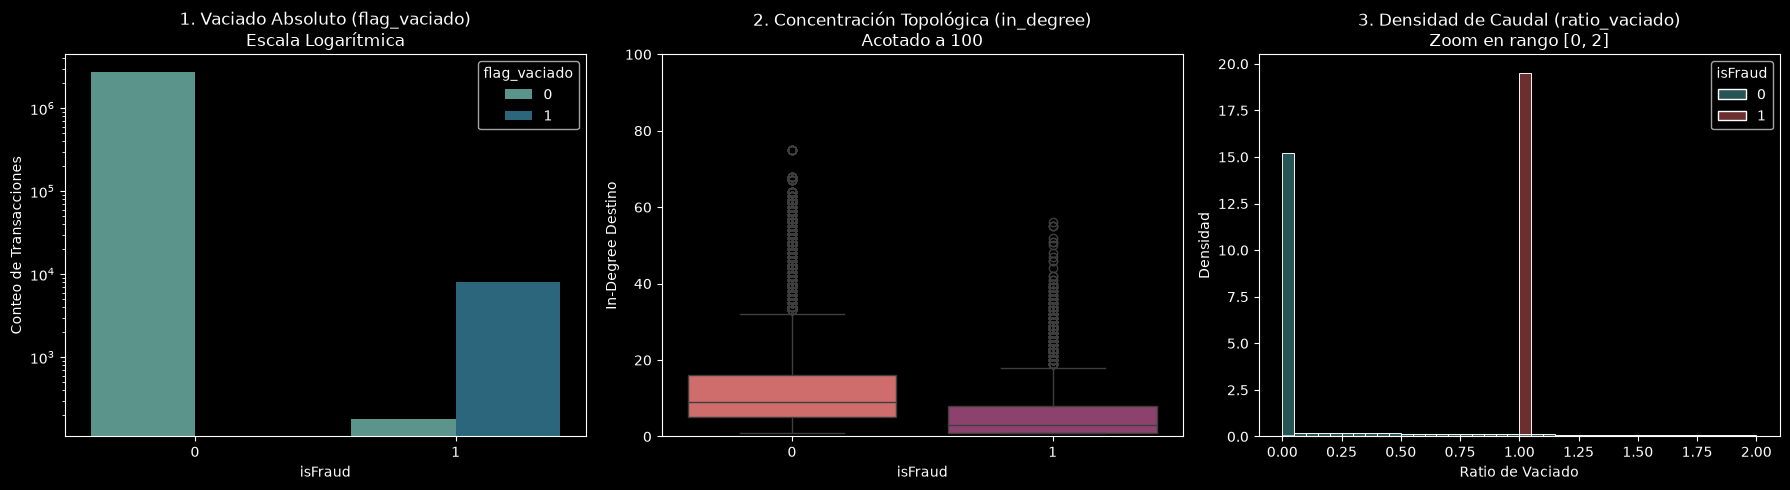

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gráfico de Vaciado Absoluto
sns.countplot(
    data=df, 
    x='isFraud', 
    hue='flag_vaciado', 
    ax=axes[0], 
    palette='crest'
)
axes[0].set_yscale('log')
axes[0].set_title('1. Vaciado Absoluto (flag_vaciado)\nEscala Logarítmica')
axes[0].set_xlabel('isFraud')
axes[0].set_ylabel('Conteo de Transacciones')

# 2. Gráfico de Concentración Topológica (In-Degree)
sns.boxplot(
    data=df, 
    x='isFraud', 
    y='in_degree', 
    hue='isFraud', 
    legend=False, 
    ax=axes[1], 
    palette='flare'
)
axes[1].set_ylim(0, 100)
axes[1].set_title('2. Concentración Topológica (in_degree)\nAcotado a 100')
axes[1].set_xlabel('isFraud')
axes[1].set_ylabel('In-Degree Destino')

# 3. Gráfico de Densidad del Ratio de Vaciado
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2], 
    x='ratio_vaciado', 
    hue='isFraud', 
    bins=40, 
    stat='density', 
    common_norm=False, 
    palette=['#4fa8a8', '#d65f5f'], 
    ax=axes[2]
)
axes[2].set_title('3. Densidad de Caudal (ratio_vaciado)\nZoom en rango [0, 2]')
axes[2].set_xlabel('Ratio de Vaciado')
axes[2].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

### Lectura del Panel de Control
- **Gráfico 1 (Vaciado):** El 97.8% del fraude presenta vaciado absoluto (`flag_vaciado = 1`), mientras que en el tráfico legítimo esta condición es marginal.
- **Gráfico 2 (Topología):** Las cuentas de destino en fraude exhiben un `in_degree` significativamente más bajo (mediana < 10) frente a las pasarelas y comercios legítimos.
- **Gráfico 3 (Caudal):** La densidad de fraude presenta una concentración casi unifrecuencia en 1.0, evidenciando ausencia de ataques de drenado fraccionado en PaySim.

## 8. Conclusiones de la Exploración de Sensores

1. **Válvula de Caudal (`ratio_vaciado`):** El 97.8% de las transacciones fraudulentas vacían la cuenta en su totalidad (`ratio_vaciado = 1.0`). No existe evidencia empírica de vaciados parciales deliberados en PaySim, pero la variable se conserva para otorgar flexibilidad al modelo ante bordes suaves o inconsistencias contables.
2. **Grosor de Tubería (`frecuencia_conexion`):** En los datos reales de PaySim, todas las conexiones tienen una frecuencia fija de 1 (ataques *hit-and-run*). La validación controlada en el entorno sintético aislado demostró que la recurrencia pura es ambigua y no discrimina por sí sola (ej. nóminas legítimas también generan alta frecuencia). Su utilidad depende de la interacción multivariable con las señales de vaciado y topología.
3. **Anomalías de Datos Registradas:** Se documentaron 29 operaciones de fraude donde `amount > oldbalanceOrg` (provocando ratios atípicos de hasta 29.5), atribuidas a artefactos de simulación o sobregiros no balanceados que XGBoost procesará en el siguiente paso.

## 9. Sellado y Exportación de la Tubería (V2)
Exportamos el dataset resultante a un archivo nuevo (`paysim_features_v2.parquet`) sin sobreescribir la entrada original. Realizamos aserciones de control para certificar que el archivo exportado mantiene exactamente las 2,770,409 transacciones reales y cero contaminación sintética.

In [41]:
# 1. Definición de la ruta de salida
ruta_destino = '../data/processed/paysim_features_v2.parquet'

# 2. Verificación de integridad: el DataFrame real nunca tocó df_sim
filas_esperadas = 2770409
assert len(df) == filas_esperadas, f"Error: Se detectaron {len(df)} filas en lugar de {filas_esperadas}"
assert 'C_MULA_TEST' not in df['nameOrig'].values, "Error crítico: El dataset contiene cuentas sintéticas de prueba."

# 3. Exportación a formato Parquet
df.to_parquet(ruta_destino, index=False)

print(f"Exportación exitosa a: {ruta_destino}")
print(f"Total de registros exportados: {len(df):,}")
print(f"Columnas finales en V2 ({len(df.columns)}): {list(df.columns)}")

Exportación exitosa a: ../data/processed/paysim_features_v2.parquet
Total de registros exportados: 2,770,409
Columnas finales en V2 (19): ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'in_degree', 'out_degree', 'flag_vaciado', 'ratio_vaciado', 'frecuencia_transacciones', 'frecuencia_conexion_x', 'frecuencia_conexion_y', 'frecuencia_conexion']
